# 1. Montamos drive

In [1]:
import pandas as pd
import numpy as np
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcdefaults()

drive.mount('/content/drive')
ruta=r"/content/drive/MyDrive/Colab Notebooks/dataset_demanda_pan_v3final.xlsx"

df=pd.read_excel(ruta)

Mounted at /content/drive


# 2. Exploramos los datos

In [2]:
df=df.dropna(axis=1)
df['Fecha']=pd.to_datetime(df['Fecha'])
df

,Fecha,Ventas en Panes,Feriado,Feriado_Largo,Temporada_Escolar,Invierno
0,2024-01-02,4535,0,0,0,0
1,2024-01-03,4475,0,0,0,0
2,2024-01-04,4525,0,0,0,0
3,2024-01-05,4611,0,0,0,0
4,2024-01-06,5150,0,0,0,0
...,...,...,...,...,...,...
676,2026-03-04,5180,0,0,0,0
677,2026-03-05,5374,0,0,0,0
678,2026-03-06,5627,0,0,0,0
679,2026-03-09,6051,0,0,0,0


# 3. Se verifíca la calidad de datos

In [3]:
display(df.isnull().sum())
print("\nNota: Ningun valor faltante")

,0
Fecha,0
Ventas en Panes,0
Feriado,0
Feriado_Largo,0
Temporada_Escolar,0
Invierno,0



Nota: Ningun valor faltante


In [4]:
display(df.info())
print("\nNota: Variables con tipo de dato correctos")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 681 entries, 0 to 680
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Fecha              681 non-null    datetime64[ns]
 1   Ventas en Panes    681 non-null    int64         
 2   Feriado            681 non-null    int64         
 3   Feriado_Largo      681 non-null    int64         
 4   Temporada_Escolar  681 non-null    int64         
 5   Invierno           681 non-null    int64         
dtypes: datetime64[ns](1), int64(5)
memory usage: 32.1 KB


None


Nota: Variables con tipo de dato correctos


# 4. Estadísticos Descriptivos

In [5]:
display(df.describe().T)
print("""\nNota: \n-Se observa que las ventas en panes tiene una media de 5793 y mediana de 5740 lo que indica que no existen muchos valores alejados del promedio.
-Los feriados tienen una frecuencia del 1.6 %.
-Los feriados largos tienen una frecuencia del 0.7 %.
-La temporada escolar tiene una frecuencia del 62.7 %.
-Invierno tiene una frecuencia del 23 %.""")

,count,mean,min,25%,50%,75%,max,std
Fecha,681,2025-02-02 19:14:32.246696448,2024-01-02 00:00:00,2024-07-18 00:00:00,2025-02-04 00:00:00,2025-08-21 00:00:00,2026-03-10 00:00:00,NaN
Ventas en Panes,681.0,5796.193833,4475.0,5438.0,5740.0,6122.0,7526.0,473.04129
Feriado,681.0,0.016153,0.0,0.0,0.0,0.0,1.0,0.126155
Feriado_Largo,681.0,0.007342,0.0,0.0,0.0,0.0,1.0,0.085434
Temporada_Escolar,681.0,0.627019,0.0,0.0,1.0,1.0,1.0,0.483953
Invierno,681.0,0.230543,0.0,0.0,0.0,0.0,1.0,0.42149



Nota: 
-Se observa que las ventas en panes tiene una media de 5793 y mediana de 5740 lo que indica que no existen muchos valores alejados del promedio.
-Los feriados tienen una frecuencia del 1.6 %.
-Los feriados largos tienen una frecuencia del 0.7 %.
-La temporada escolar tiene una frecuencia del 62.7 %.
-Invierno tiene una frecuencia del 23 %.


# 5. Creación de variables de rezagos y media movil

In [6]:
def lag(n,df):
  df=df.copy()
  df[f"lag_{n}"]=df["Ventas en Panes"].shift(n)
  return df

def media_movil(n,df):
  df=df.copy()
  df[f"media_movil_{n}"]=df["Ventas en Panes"].shift(1).rolling(n).mean()
  return df

df=lag(1,df)  # Registro del dia anterior
df=lag(2,df)  # Registro de hace 2 dias
df=lag(6,df)  # Registro de hace 6 dias
df=media_movil(3,df)  # Promedio de los ultimos 3 registros

df=df.dropna()

df2=df.copy()  # creamos una copia para trabajar con nuestro pipeline mas adelante
df

,Fecha,Ventas en Panes,Feriado,Feriado_Largo,Temporada_Escolar,Invierno,lag_1,lag_2,lag_6,media_movil_3
6,2024-01-09,5255,0,0,0,0,6099.0,5150.0,4535.0,5286.666667
7,2024-01-10,4861,0,0,0,0,5255.0,6099.0,4475.0,5501.333333
8,2024-01-11,4900,0,0,0,0,4861.0,5255.0,4525.0,5405.000000
9,2024-01-12,5340,0,0,0,0,4900.0,4861.0,4611.0,5005.333333
10,2024-01-13,5674,0,0,0,0,5340.0,4900.0,5150.0,5033.666667
...,...,...,...,...,...,...,...,...,...,...
676,2026-03-04,5180,0,0,0,0,5453.0,6252.0,5359.0,5916.333333
677,2026-03-05,5374,0,0,0,0,5180.0,5453.0,5120.0,5628.333333
678,2026-03-06,5627,0,0,0,0,5374.0,5180.0,5313.0,5335.666667
679,2026-03-09,6051,0,0,0,0,5627.0,5374.0,6044.0,5393.666667


# 6. EDA

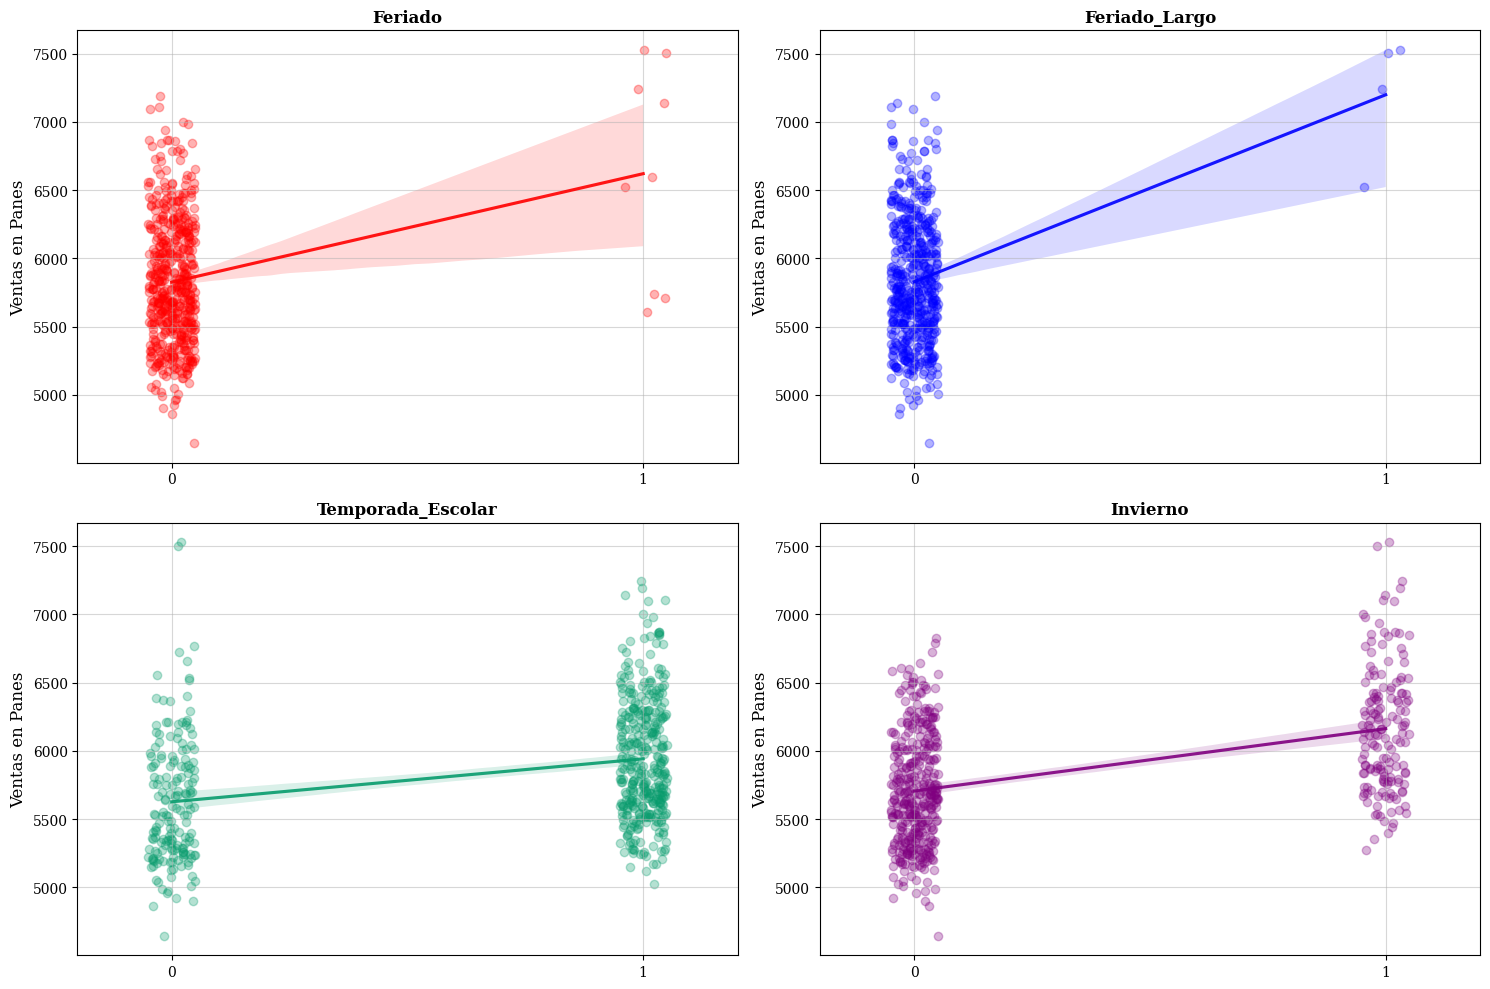


Nota:
-Se oservan pocas observaciones cuando ocurre un Feriado o Feriado Largo.
-Se observa que ligeramente aumentas las ventas cuando se presenta invierno y temporada escolar.
-Se observa que la tendencia mas marcada es la de feriado Largo.


In [7]:


## se crea una función de formato para los ejes

def estilo_ejes(fontweight,n,title_x,title_y):
  n.set_xlabel(title_x,fontname="DejaVu Serif",fontsize=12)
  n.set_ylabel(title_y,fontname="DejaVu Serif",fontsize=12)
  n.tick_params(axis='both', labelsize=12)
  n.tick_params(axis="both",colors="black",labelsize=10)
  plt.setp(n.get_xticklabels(), fontweight=fontweight,fontname="DejaVu Serif")
  plt.setp(n.get_yticklabels(), fontweight=fontweight,fontname="DejaVu Serif")





df["Dia"]=df["Fecha"].dt.day_name()
df["Año"]=df["Fecha"].dt.year
df["Mes"]=df["Fecha"].dt.month_name()

train_size=int(len(df)*0.8)

X_train=df.iloc[:train_size]
Y_train=df.iloc[:train_size]
X_test=df.iloc[train_size:]
Y_test=df.iloc[train_size:]

Enteros=df.select_dtypes(include="int").columns.tolist()
excluir=["Ventas en Panes","Año"]
Binarias=[c for c in Enteros if c not in excluir]


color=["red","blue","#079C6D","purple"]
n=0
fig,axes=plt.subplots(2,2,figsize=(15,10))
for ax,i in zip(axes.flat,Binarias):
  sns.regplot(ax=ax,data=X_train,x=X_train[i],y=X_train["Ventas en Panes"],scatter_kws={"alpha": 0.3,"color":color[n]},
             line_kws={"alpha": 0.9,"color":color[n]},x_jitter=0.05)
  ax.grid(alpha=0.5)
  ax.set_title(f"{i}",fontname="DejaVu Serif",fontweight="bold")
  ax.set_xlim(-0.2, 1.2)
  ax.set_xticks([0, 1])
  estilo_ejes(None,ax,None,"Ventas en Panes")
  n+=1
plt.tight_layout()
plt.show()

print("""\nNota:\n-Se oservan pocas observaciones cuando ocurre un Feriado o Feriado Largo.
-Se observa que ligeramente aumentas las ventas cuando se presenta invierno y temporada escolar.
-Se observa que la tendencia mas marcada es la de feriado Largo.""")


## 6.1 Tendencia Semanal,mensual y anual

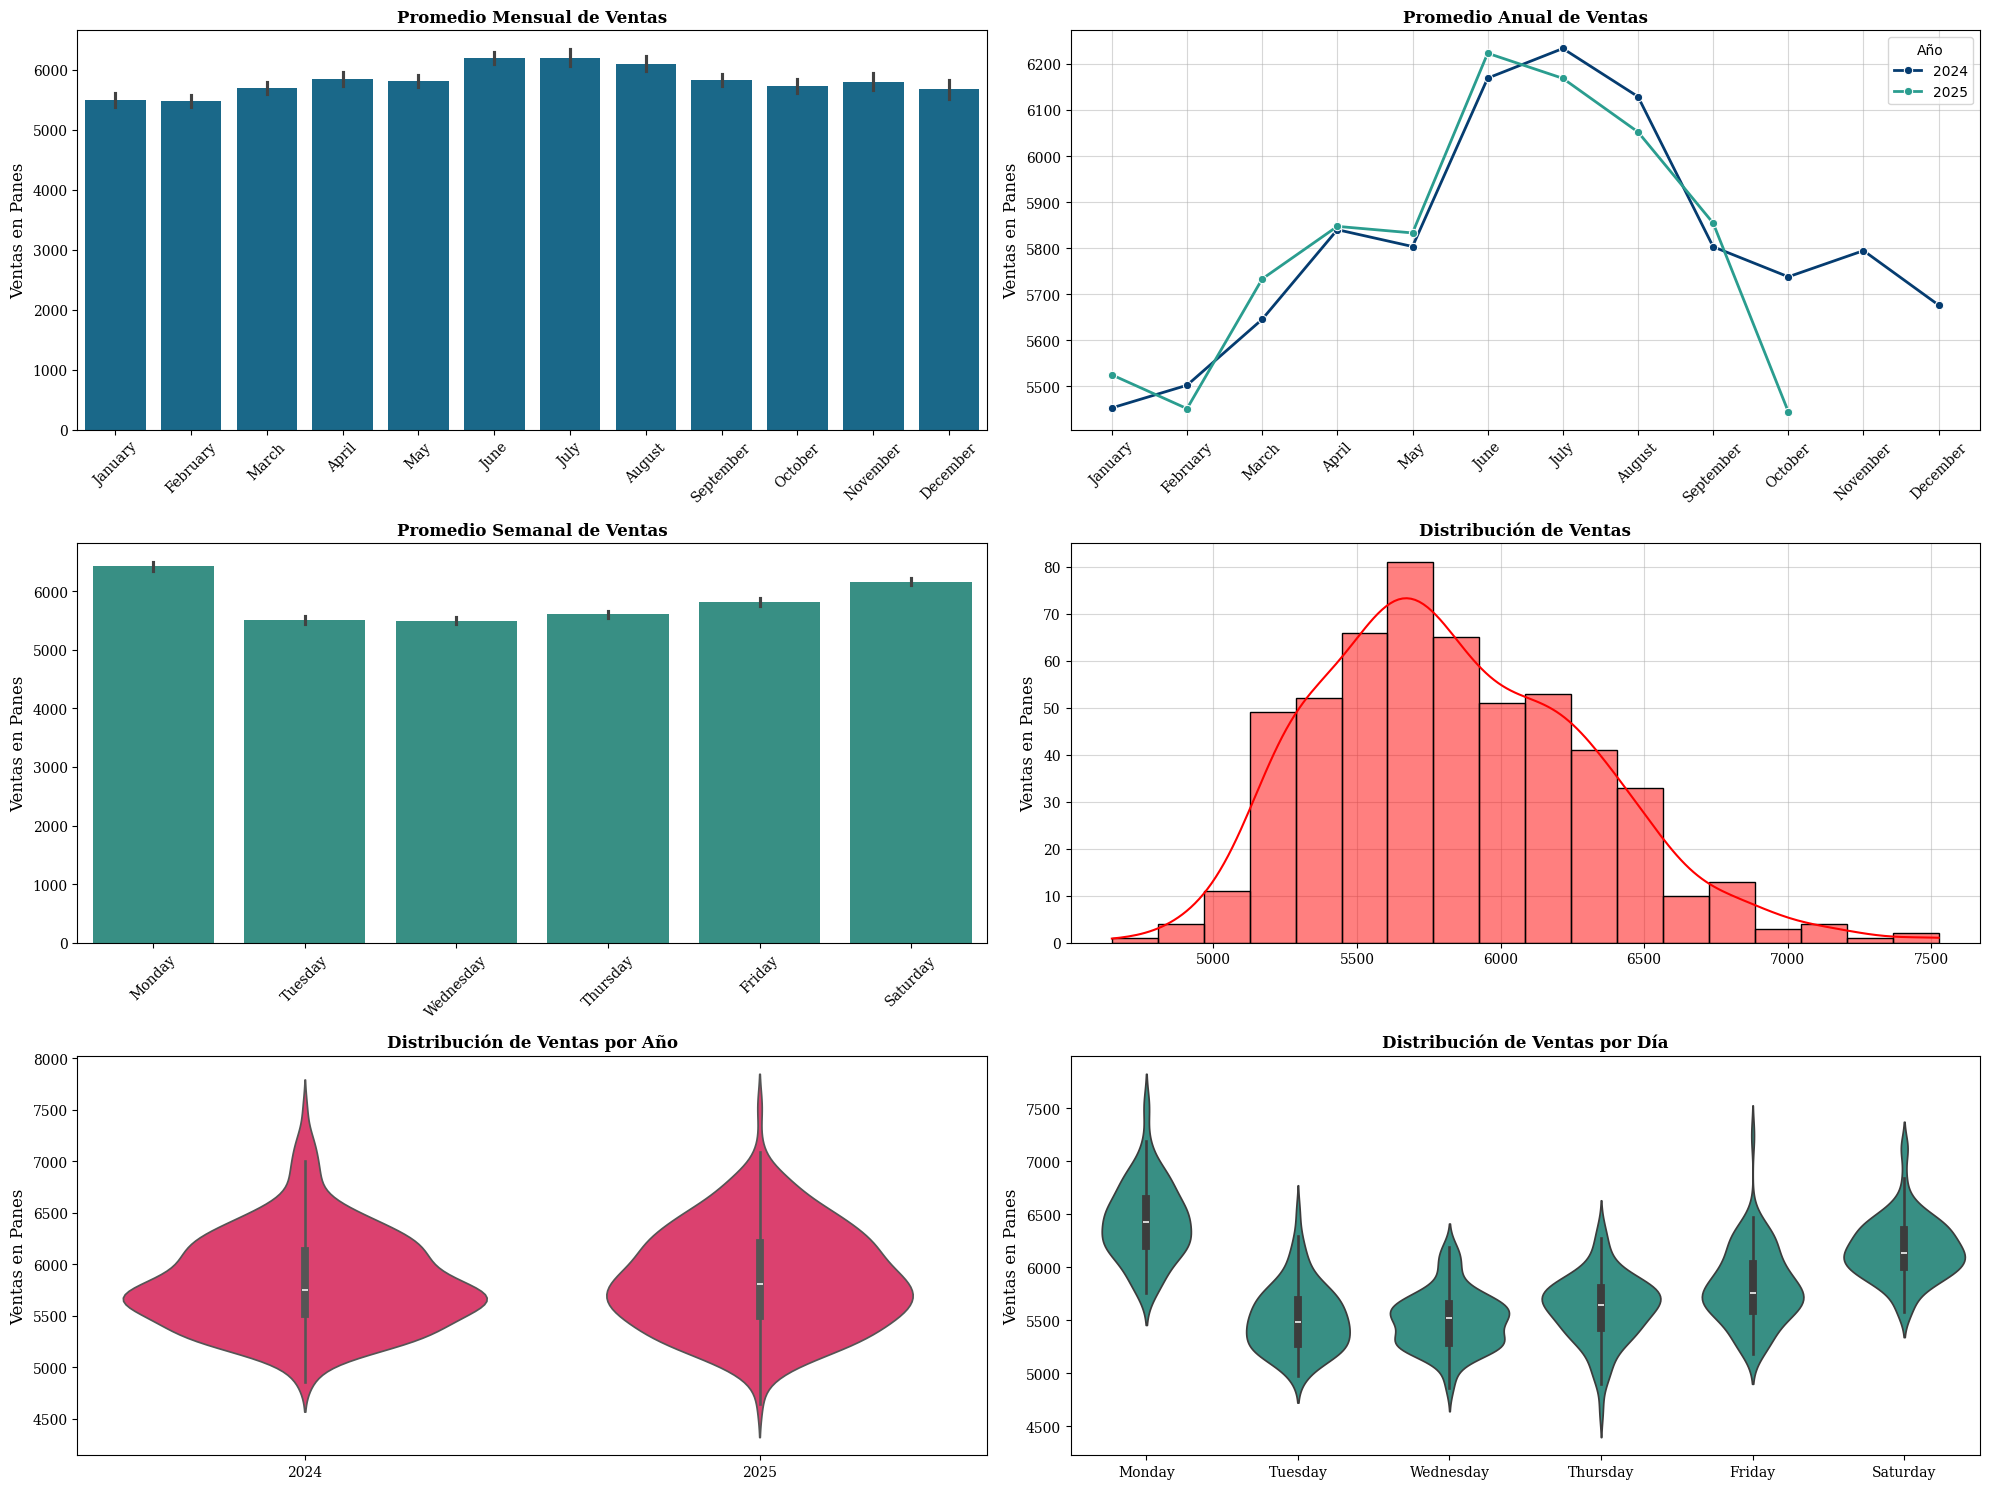


Nota:
-Se observa una tendencia mensual marcada en los meses Junio-Julio y Agosto.
-Los días donde hay un mayor promedio de ventas son los Lunes-Viernes y sabados.
-Las mayor frecuencia de ventas se encuentra entre 5500-6000 unidades.
-Los meses de menores ventas son Enero y Febrero. 


In [8]:


order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday"]


fig,ax=plt.subplots(3,2,figsize=(20,15))
sns.barplot(ax=ax[0,0],data=X_train,x="Mes",y="Ventas en Panes",estimator="mean",color="#076F9C")
ax[0,0].set_title("Promedio Mensual de Ventas",fontname="DejaVu Serif",fontweight="bold")
ax[0,0].set_xlabel("Mes",fontname="DejaVu Serif")
ax[0,0].set_ylabel("Ventas en Panes",fontname="DejaVu Serif")
estilo_ejes(None,ax[0,0],None,"Ventas en Panes")
ax[0, 0].tick_params(axis="x", labelrotation=45)


sns.lineplot(ax=ax[0,1],data=X_train,x="Mes",y="Ventas en Panes",hue="Año",marker="o",color="red",errorbar=None,palette=["#053C70","#2A9D8F"],linewidth=2)
ax[0,1].set_title("Promedio Anual de Ventas",fontname="DejaVu Serif",fontweight="bold")
ax[0,1].set_xlabel("Mes",fontname="DejaVu Serif")
ax[0,1].set_ylabel("Ventas en Panes",fontname="DejaVu Serif")
ax[0,1].grid(alpha=0.5)
estilo_ejes(None,ax[0,1],None,"Ventas en Panes")
ax[0,1].tick_params(axis="x", labelrotation=45)


sns.barplot(ax=ax[1,0],data=X_train,x="Dia",y="Ventas en Panes",estimator="mean",color="#2A9D8F",order=order)
ax[1,0].set_title("Promedio Semanal de Ventas",fontname="DejaVu Serif",fontweight="bold")
ax[1,0].set_xlabel("Mes",fontname="DejaVu Serif")
ax[1,0].set_ylabel("Ventas en Panes",fontname="DejaVu Serif")
estilo_ejes(None,ax[1,0],None,"Ventas en Panes")
ax[1,0].tick_params(axis="x", labelrotation=45)


sns.histplot(ax=ax[1,1],data=X_train,x="Ventas en Panes",color="red",kde=True)
ax[1,1].set_title("Distribución de Ventas",fontname="DejaVu Serif",fontweight="bold")
ax[1,1].set_xlabel("Mes",fontname="DejaVu Serif")
ax[1,1].set_ylabel("Ventas en Panes",fontname="DejaVu Serif")
ax[1,1].grid(alpha=0.5)
ax[1,1].set_axisbelow(True)
estilo_ejes(None,ax[1,1],None,"Ventas en Panes")


sns.violinplot(ax=ax[2,0],data=X_train,x="Año",y="Ventas en Panes",color="#F52765")
ax[2,0].set_title("Distribución de Ventas por Año",fontname="DejaVu Serif",fontweight="bold")
ax[2,0].set_xlabel("Mes",fontname="DejaVu Serif")
ax[2,0].set_ylabel("Ventas en Panes",fontname="DejaVu Serif")
ax[2,0].set_axisbelow(True)
estilo_ejes(None,ax[2,0],None,"Ventas en Panes")

sns.violinplot(ax=ax[2,1],data=X_train,x="Dia",y="Ventas en Panes",color="#2A9D8F",order=order)
ax[2,1].set_title("Distribución de Ventas por Día",fontname="DejaVu Serif",fontweight="bold")
ax[2,1].set_xlabel("Mes",fontname="DejaVu Serif")
ax[2,1].set_ylabel("Ventas en Panes",fontname="DejaVu Serif")
ax[2,1].set_axisbelow(True)
estilo_ejes(None,ax[2,1],None,"Ventas en Panes")
plt.tight_layout()
plt.show()

print("""\nNota:\n-Se observa una tendencia mensual marcada en los meses Junio-Julio y Agosto.
-Los días donde hay un mayor promedio de ventas son los Lunes-Viernes y sabados.
-Las mayor frecuencia de ventas se encuentra entre 5500-6000 unidades.
-Los meses de menores ventas son Enero y Febrero. """)





# 7. Pipeline de Preprocesamiento

In [9]:

import numpy as np
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import root_mean_squared_error



X_train=X_train.drop(["Ventas en Panes","Año","Mes","Dia"],axis=1)
Y_train=Y_train["Ventas en Panes"]
X_test=X_test.drop(["Ventas en Panes","Año","Mes","Dia"],axis=1)
Y_test=Y_test["Ventas en Panes"]



def mes_num(x):
  return x["Fecha"].dt.month.to_frame()

def dia(x):
  return x["Fecha"].dt.day_name().to_frame()

def semana(x):
  return x["Fecha"].dt.isocalendar().week.to_frame(name="Fecha")

def cyclical_transform(X):
    X = np.asarray(X)
    return np.column_stack([
        np.sin(2 * np.pi * (X - 1) / 12),
        np.cos(2 * np.pi * (X - 1) / 12)
    ])
def nombres_ciclicos(transformer, input_features):
    return ["Mes_sin", "Mes_cos"]


semana_trans=FunctionTransformer(semana,feature_names_out="one-to-one")


transformer=make_pipeline(FunctionTransformer(mes_num,feature_names_out="one-to-one"),
                          FunctionTransformer(cyclical_transform,feature_names_out=nombres_ciclicos))

categorias=make_pipeline(FunctionTransformer(dia,feature_names_out="one-to-one"),
                         OneHotEncoder(handle_unknown="ignore",drop="first"))



preprocesador=ColumnTransformer([("Mes",transformer,["Fecha"]),
                                 ("Dia",categorias,["Fecha"]),
                                 ("Semana",semana_trans,["Fecha"])],
                                remainder="passthrough")

datos_preparados=preprocesador.fit_transform(X_train)
print("Variables generadas por el Pipeline de preprocesamiento: ")
for col in preprocesador.get_feature_names_out():
    print(f"{col}")


Variables generadas por el Pipeline de preprocesamiento: 
Mes__Mes_sin
Mes__Mes_cos
Dia__Fecha_Monday
Dia__Fecha_Saturday
Dia__Fecha_Thursday
Dia__Fecha_Tuesday
Dia__Fecha_Wednesday
Semana__Fecha
remainder__Feriado
remainder__Feriado_Largo
remainder__Temporada_Escolar
remainder__Invierno
remainder__lag_1
remainder__lag_2
remainder__lag_6
remainder__media_movil_3


# 8. Entrenamiento de Modelos

## 8.1 Regresión Lineal

In [10]:

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
reg_pipe=Pipeline([("preprocesador",preprocesador),("escalador",StandardScaler()),
                  ("regresion",LinearRegression())])


tscv = TimeSeriesSplit(n_splits=10)

lin_rmse=-cross_val_score(reg_pipe,X_train,Y_train,scoring="neg_root_mean_squared_error",cv=tscv)

reg_pipe.fit(X_train,Y_train)
rmse_rg=root_mean_squared_error(Y_train,reg_pipe.predict(X_train))

print(f"RMSE train de Regresión Lineal: {np.round(rmse_rg,2)} Un")
print(f"CV RMSE medio Regresión Lineal: {np.round(lin_rmse.mean(),2)} Un")
print(f"CV RMSE STD Regresión Lineal: {np.round(lin_rmse.std(),2)} Un")
print("\nNota:\n-Desempeño relativamente consistente entre entrenamiento y validación cruzada.")

RMSE train de Regresión Lineal: 169.76 Un
CV RMSE medio Regresión Lineal: 205.8 Un
CV RMSE STD Regresión Lineal: 45.23 Un

Nota:
-Desempeño relativamente consistente entre entrenamiento y validación cruzada.


## 8.2 Random Forest

In [11]:

from sklearn.ensemble import RandomForestRegressor

rd_pipe=Pipeline([("preprocesador",preprocesador),
                  ("Random_Forest",RandomForestRegressor(random_state=45))])



rd_rmse=-cross_val_score(rd_pipe,X_train,Y_train,scoring="neg_root_mean_squared_error",cv=tscv)

rd_pipe.fit(X_train,Y_train)
rmse_rd=root_mean_squared_error(Y_train,rd_pipe.predict(X_train))

print(f"RMSE train de Random forest : {np.round(rmse_rd,2)} Un")
print(f"CV RMSE medio Random forest: {np.round(rd_rmse.mean(),2)} Un")
print(f"CV RMSE STD Random forest: {np.round(rd_rmse.std(),2)} Un")
print("\nNota:\n-Modelo con indicio de overfiting ya que el rmse train y cv train cambian radicalmente.")

RMSE train de Random forest : 86.39 Un
CV RMSE medio Random forest: 260.95 Un
CV RMSE STD Random forest: 55.39 Un

Nota:
-Modelo con indicio de overfiting ya que el rmse train y cv train cambian radicalmente.


## 8.3 XGBOOST

In [12]:

from xgboost import XGBRegressor

xg_pipe=Pipeline([("preprocesador",preprocesador),
                  ("XGBRegressor",XGBRegressor(random_state=45))])



xg_rmse=-cross_val_score(xg_pipe,X_train,Y_train,scoring="neg_root_mean_squared_error",cv=tscv)

xg_pipe.fit(X_train,Y_train)
rmse_xg=root_mean_squared_error(Y_train,xg_pipe.predict(X_train))

print(f"RMSE train de XGBRegressor : {np.round(rmse_xg,2)} Un")
print(f"CV RMSE medio XGBRegressor: {np.round(xg_rmse.mean(),2)} Un")
print(f"CV RMSE STD XGBRegressor: {np.round(xg_rmse.std(),2)} Un")
print("\nNota:\n-Modelo con indicio de overfiting ya que el rmse train y cv train cambian radicalmente.")

RMSE train de XGBRegressor : 7.18 Un
CV RMSE medio XGBRegressor: 273.1 Un
CV RMSE STD XGBRegressor: 56.27 Un

Nota:
-Modelo con indicio de overfiting ya que el rmse train y cv train cambian radicalmente.


# 9. RandomizedSearchCV

## 9.1 Random forest

In [13]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint,uniform

Random_pipeline=Pipeline([("preprocesador",preprocesador),
                  ("Random_Forest",RandomForestRegressor(random_state=45,))])



param={'Random_Forest__n_estimators': randint(100,300),
       'Random_Forest__max_depth': randint(1,10),
       'Random_Forest__min_samples_split': randint(2, 11),
       'Random_Forest__min_samples_leaf': randint(1, 5),
       'Random_Forest__max_features': uniform(0.5,0.5)}

rnd_search=RandomizedSearchCV(Random_pipeline,param_distributions=param,
                              n_iter=10,
                              cv=tscv,scoring='neg_root_mean_squared_error',
                              random_state=42,n_jobs=-1)

rnd_search.fit(X_train,Y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=10, test_size=None),
                   estimator=Pipeline(steps=[('preprocesador',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('Mes',
                                                                               Pipeline(steps=[('functiontransformer-1',
                                                                                                FunctionTransformer(feature_names_out='one-to-one',
                                                                                                                    func=<function mes_num at 0x792c78f2c220>)),
                                                                                               ('functiontransform...
                                        'Random_Forest__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792c6a6be9e0>,
                                        'Random_Forest__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792c6a624a50>,
                                        'Random_Forest__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792c6b997e00>},
                   random_state=42, scoring='neg_root_mean_squared_error')

## 9.2 Resultados Random Forest

In [14]:
print('=== Mejores hiperparámetros (RandomizedSearch) ===')
print(rnd_search.best_params_)
print()

best_rmse_rnd = -rnd_search.best_score_
print(f'Mejor RMSE (CV media): {best_rmse_rnd:,.0f}')
print()



=== Mejores hiperparámetros (RandomizedSearch) ===
{'Random_Forest__max_depth': 7, 'Random_Forest__max_features': np.float64(0.5852620618436457), 'Random_Forest__min_samples_leaf': 3, 'Random_Forest__min_samples_split': 3, 'Random_Forest__n_estimators': 231}

Mejor RMSE (CV media): 253



## 9.3 XGBOOST

In [15]:

xg_pipeline=Pipeline([("preprocesador",preprocesador),
                  ("XGBoost",XGBRegressor(random_state=45,))])



param_xg={ 'XGBoost__n_estimators': randint(100, 301),
    'XGBoost__max_depth': randint(2, 11),
    'XGBoost__learning_rate': uniform(0.01, 0.29),
    'XGBoost__subsample': uniform(0.6, 0.4),
    'XGBoost__colsample_bytree': uniform(0.6, 0.4)}

xg_search=RandomizedSearchCV(xg_pipeline,param_distributions=param_xg,
                              n_iter=10,
                              cv=tscv,scoring='neg_root_mean_squared_error',
                              random_state=42,n_jobs=-1)

xg_search.fit(X_train,Y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=10, test_size=None),
                   estimator=Pipeline(steps=[('preprocesador',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('Mes',
                                                                               Pipeline(steps=[('functiontransformer-1',
                                                                                                FunctionTransformer(feature_names_out='one-to-one',
                                                                                                                    func=<function mes_num at 0x792c78f2c220>)),
                                                                                               ('functiontransform...
                                        'XGBoost__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792c6a5bd010>,
                                        'XGBoost__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792c6a56c050>,
                                        'XGBoost__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x792c6a6251d0>},
                   random_state=42, scoring='neg_root_mean_squared_error')

## 9.4 Resultados XGBOOST

In [16]:
print('=== Mejores hiperparámetros (RandomizedSearch) ===')
print(xg_search.best_params_)
print()

best_rmse_xg = -xg_search.best_score_
print(f'Mejor RMSE (CV media): {best_rmse_xg:,.0f}')
print()


=== Mejores hiperparámetros (RandomizedSearch) ===
{'XGBoost__colsample_bytree': np.float64(0.8099025726528951), 'XGBoost__learning_rate': np.float64(0.13526405540621358), 'XGBoost__max_depth': 2, 'XGBoost__n_estimators': 158, 'XGBoost__subsample': np.float64(0.7599443886861021)}

Mejor RMSE (CV media): 240



# 10. Importancia de Variables

## 10.1 Random Forest

In [17]:
rnd_final=rnd_search.best_estimator_
feature_importances=rnd_final["Random_Forest"].feature_importances_
features_names=rnd_final["preprocesador"].get_feature_names_out()


importancias_rnd=pd.DataFrame({"Feature":features_names,
                           "Importancia":feature_importances}).sort_values('Importancia',ascending=False).reset_index(drop=True)


print('=== Top 15 features más importantes ===')
print(importancias_rnd.head(15).to_string(index=False, float_format='{:.4f}'.format))


=== Top 15 features más importantes ===
                     Feature  Importancia
            remainder__lag_6       0.5632
           Dia__Fecha_Monday       0.1004
            remainder__lag_1       0.0808
                Mes__Mes_cos       0.0414
    remainder__media_movil_3       0.0368
            remainder__lag_2       0.0356
         Dia__Fecha_Saturday       0.0311
         remainder__Invierno       0.0304
               Semana__Fecha       0.0298
          Dia__Fecha_Tuesday       0.0164
remainder__Temporada_Escolar       0.0161
          remainder__Feriado       0.0062
                Mes__Mes_sin       0.0044
         Dia__Fecha_Thursday       0.0031
        Dia__Fecha_Wednesday       0.0030


## 10.2 XGBOOST

In [18]:
xg_final=xg_search.best_estimator_
feature_importances_xg=xg_final["XGBoost"].feature_importances_
features_names_xg=xg_final["preprocesador"].get_feature_names_out()


importancias_xg=pd.DataFrame({"Feature":features_names_xg,
                           "Importancia":feature_importances_xg}).sort_values('Importancia',ascending=False).reset_index(drop=True)


print('=== Top 15 features más importantes ===')
print(importancias_xg.head(15).to_string(index=False, float_format='{:.4f}'.format))

=== Top 15 features más importantes ===
                     Feature  Importancia
           Dia__Fecha_Monday       0.2774
         remainder__Invierno       0.2357
            remainder__lag_6       0.1079
         Dia__Fecha_Saturday       0.0874
    remainder__Feriado_Largo       0.0536
          remainder__Feriado       0.0532
remainder__Temporada_Escolar       0.0363
               Semana__Fecha       0.0300
                Mes__Mes_cos       0.0254
          Dia__Fecha_Tuesday       0.0204
    remainder__media_movil_3       0.0176
            remainder__lag_1       0.0148
            remainder__lag_2       0.0141
        Dia__Fecha_Wednesday       0.0123
         Dia__Fecha_Thursday       0.0083


## 10.3 Importancias Random Forest vs Xgboost

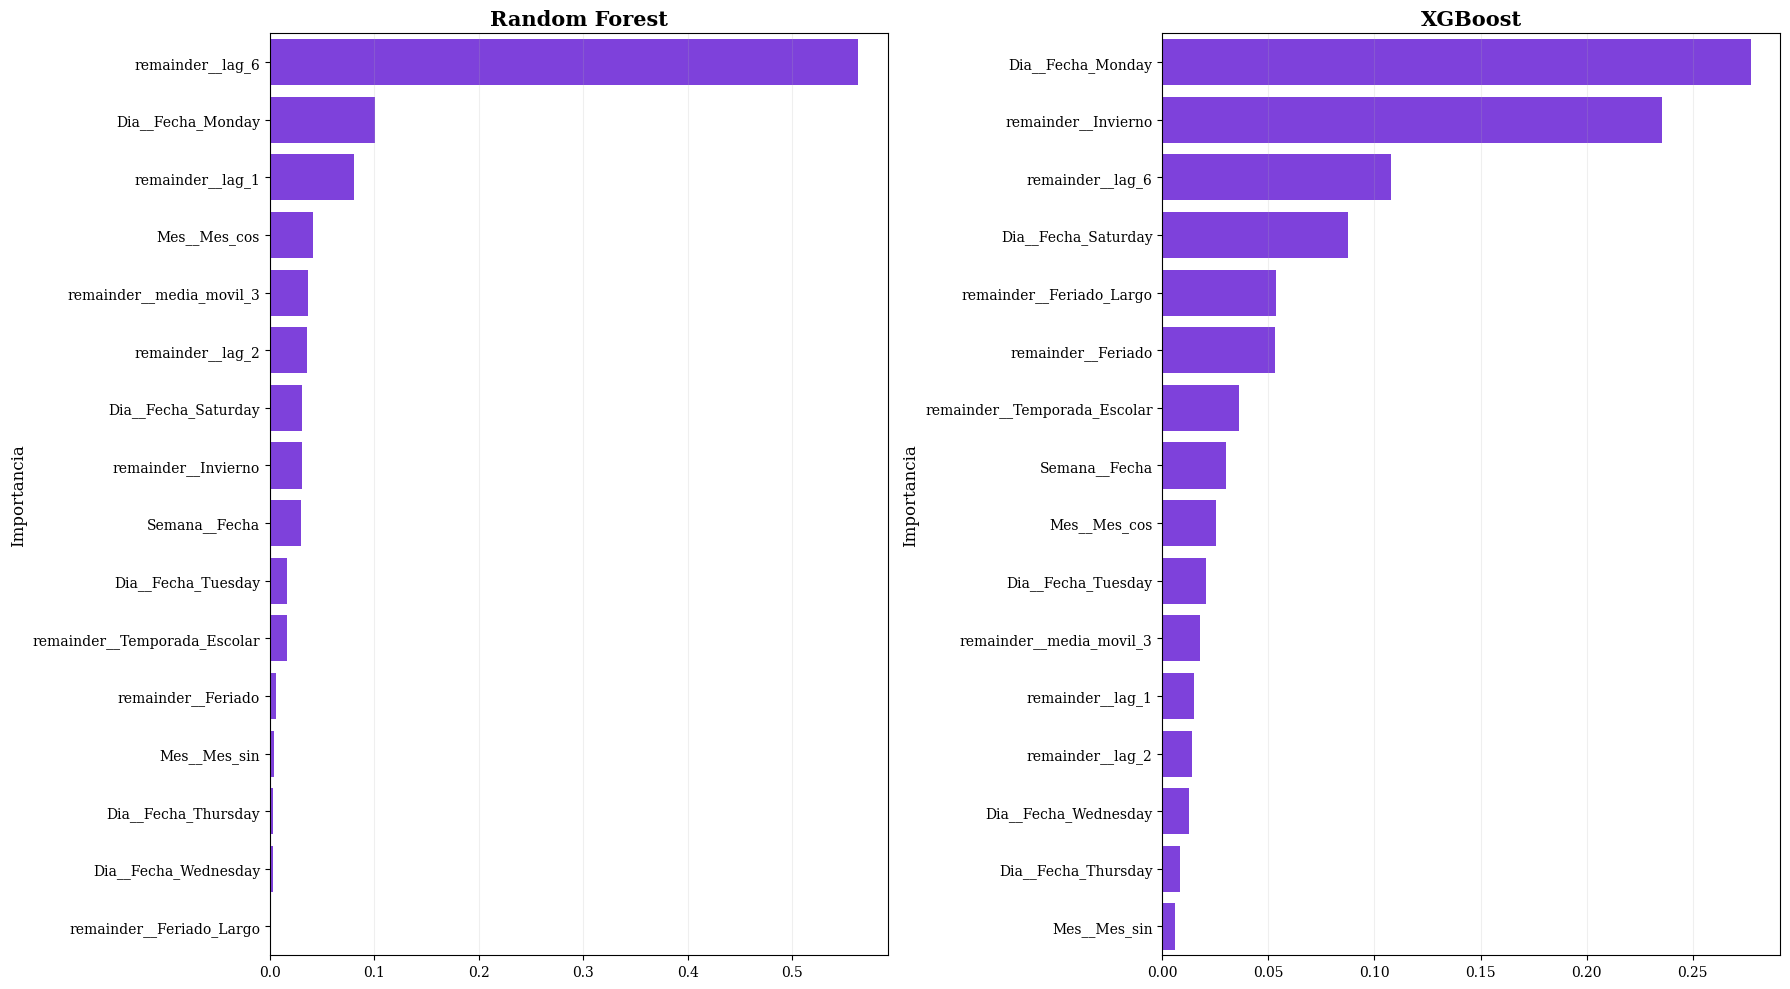

In [19]:
fig,axes=plt.subplots(1,2,figsize=(18,10))
sns.barplot(ax=axes[0],data=importancias_rnd,x="Importancia",y="Feature",color='#7927F5')
axes[0].set_title("Random Forest",fontname="DejaVu Serif",fontweight="bold",fontsize=15)
axes[0].set_xlabel("Features",fontname="DejaVu Serif")
axes[0].set_ylabel("Importancia",fontname="DejaVu Serif")
axes[0].grid(alpha=0.2,axis="x")
estilo_ejes(None,axes[0],None,"Importancia")


sns.barplot(ax=axes[1],data=importancias_xg,x="Importancia",y="Feature",color='#7927F5')
axes[1].set_title("XGBoost",fontname="DejaVu Serif",fontweight="bold",fontsize=15)
axes[1].set_xlabel("Features",fontname="DejaVu Serif")
axes[1].set_ylabel("Importancia",fontname="DejaVu Serif")
axes[1].grid(alpha=0.2,axis="x")
estilo_ejes(None,axes[1],None,"Importancia")
fig.tight_layout()
plt.show()

# 11. Features menos útiles: ¿se pueden eliminar?

## 11.1 Select from Random Forest

In [20]:
from sklearn.feature_selection import SelectFromModel

pipe_selection_rnd=Pipeline([("preprocesador",preprocesador),
                  ("Selector",SelectFromModel(RandomForestRegressor(n_estimators=50, random_state=42),threshold="median")),
                  ("Random_Forest",RandomForestRegressor(random_state=42))])



rnd_best_params={'Random_Forest__n_estimators':rnd_search.best_params_['Random_Forest__n_estimators'] ,
       'Random_Forest__max_depth':rnd_search.best_params_['Random_Forest__max_depth'],
       'Random_Forest__min_samples_split': rnd_search.best_params_['Random_Forest__min_samples_split'],
       'Random_Forest__min_samples_leaf':rnd_search.best_params_['Random_Forest__min_samples_leaf'] ,
       'Random_Forest__max_features':rnd_search.best_params_['Random_Forest__max_features']}

pipe_selection_rnd.set_params(**rnd_best_params)

rmse_rnd_best=-cross_val_score(pipe_selection_rnd,X_train,Y_train,scoring="neg_root_mean_squared_error",cv=tscv,n_jobs=-1).mean()

print(f'RMSE con seleccion automatica de features: {rmse_rnd_best:,.0f}')
print(f'RMSE del mejor modelo (rnd_search):        {-rnd_search.best_score_:,.0f}')


RMSE con seleccion automatica de features: 268
RMSE del mejor modelo (rnd_search):        253


## 11.2 Select from xgboost

In [21]:

pipe_selection_xgb=Pipeline([("preprocesador",preprocesador),
                  ("Selector",SelectFromModel(XGBRegressor(n_estimators=50, random_state=42),threshold="median")),
                  ("XGBoost",XGBRegressor(random_state=42))])

xgb_best_params={'XGBoost__n_estimators':xg_search.best_params_['XGBoost__n_estimators'],
    'XGBoost__max_depth': xg_search.best_params_['XGBoost__max_depth'],
    'XGBoost__learning_rate':xg_search.best_params_['XGBoost__learning_rate'],
    'XGBoost__subsample': xg_search.best_params_['XGBoost__subsample'],
    'XGBoost__colsample_bytree':xg_search.best_params_['XGBoost__colsample_bytree']}

pipe_selection_xgb.set_params(**xgb_best_params)

rmse_xgb_best=-cross_val_score(pipe_selection_xgb,X_train,Y_train,scoring="neg_root_mean_squared_error",cv=tscv,n_jobs=-1).mean()

print(f'RMSE con seleccion automatica de features: {rmse_xgb_best:,.0f}')
print(f'RMSE del mejor modelo (rnd_search):        {-xg_search.best_score_:,.0f}')

RMSE con seleccion automatica de features: 249
RMSE del mejor modelo (rnd_search):        240


# 12. Evaluación Final

In [22]:
# Recuperamos el test set ya separado (lo hicimos en la seccion StratifiedShuffleSplit)
# X_test_f, y_test_f ya estan definidos en la celda 124

# Predicciones finales (el pipeline aplica todo el preprocesamiento por nosotros)
final_predictions_rnd = rnd_final.predict(X_test)
final_predictions_xg = xg_final.predict(X_test)

# RMSE en test
final_rmse_rnd = root_mean_squared_error(Y_test, final_predictions_rnd)
final_rmse_xg = root_mean_squared_error(Y_test, final_predictions_xg)
final_rmse_rl=root_mean_squared_error(Y_test,reg_pipe.predict(X_test))
rmse_baseline = root_mean_squared_error(Y_test,X_test['lag_1'])
print("==== Random Forest ====")

print(f'RMSE en CV (validacion train):     {-rnd_search.best_score_:>10,.0f}')
print(f'RMSE en TEST SET:                  {final_rmse_rnd:>10,.0f}')

print()
print("==== XGBOOST ====")
print(f'RMSE en CV (validacion train):     {-xg_search.best_score_:>10,.0f}')
print(f'RMSE en TEST SET:                  {final_rmse_xg:>10,.0f}')

print()
print("==== Regresión Lineal ====")
print(f'CV RMSE medio Regresión Lineal:    {np.round(lin_rmse.mean(),2):>10,.0f}')
print(f'RMSE en TEST SET:                  {final_rmse_rl:>10,.0f}')


==== Random Forest ====
RMSE en CV (validacion train):            253
RMSE en TEST SET:                         188

==== XGBOOST ====
RMSE en CV (validacion train):            240
RMSE en TEST SET:                         161

==== Regresión Lineal ====
CV RMSE medio Regresión Lineal:           206
RMSE en TEST SET:                         151


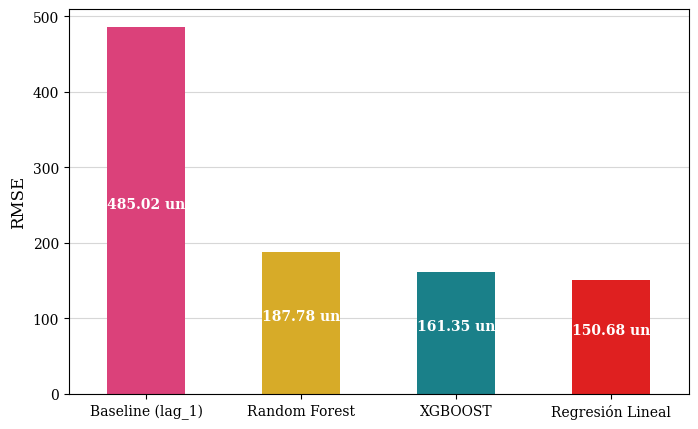

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
bars_sz=sns.barplot(x=['Random Forest', 'XGBOOST','Regresión Lineal','Baseline (lag_1)'], y=[final_rmse_rnd, final_rmse_xg,final_rmse_rl,rmse_baseline],ax=ax,palette={'#078F9C','#F52773','#F4BA0B','red'},
            hue=['Random Forest', 'XGBOOST', 'Regresión Lineal','Baseline (lag_1)'],  width=0.5,order=['Baseline (lag_1)', 'Random Forest','XGBOOST','Regresión Lineal'])

estilo_ejes(None,ax,None,"RMSE")
ax.grid(alpha=0.5,axis="y")
ax.set_axisbelow(True)
for b in bars_sz.patches:
    val = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, val/2, f"{val:.2f} un", ha='center' ,va='bottom', fontweight='bold',fontname='DejaVu Serif',color='white')
plt.show()

# 13. Intervalo de confianza con `bootstrap`

In [24]:
from scipy import stats
def rmse_de_errores_cuadraticos(errores_cuad):
    """Funcion estadistica para bootstrap: dado un array de errores al cuadrado,
    devuelve el RMSE."""
    return np.sqrt(np.mean(errores_cuad))

confianza = 0.95
errores_cuadraticos = (reg_pipe.predict(X_test) - Y_test) ** 2


resultado_boot = stats.bootstrap(
    [errores_cuadraticos],
    rmse_de_errores_cuadraticos,
    confidence_level=confianza,
    n_resamples=10_000,
    random_state=42,
)

rmse_lower, rmse_upper = resultado_boot.confidence_interval

print(f'=== Intervalo de confianza al {confianza*100:.0f}% para el RMSE ===')
print(f'  Cota inferior: {rmse_lower:>10,.0f}')
print(f'  Estimacion:    {final_rmse_rl:>10,.0f}')
print(f'  Cota superior: {rmse_upper:>10,.0f}')
print()
print(f'Es decir, con {confianza*100:.0f}% de confianza, el verdadero RMSE de generalizacion')
print(f'esta entre {rmse_lower:,.0f} y {rmse_upper:,.0f}.')

=== Intervalo de confianza al 95% para el RMSE ===
  Cota inferior:        137
  Estimacion:           151
  Cota superior:        166

Es decir, con 95% de confianza, el verdadero RMSE de generalizacion
esta entre 137 y 166.


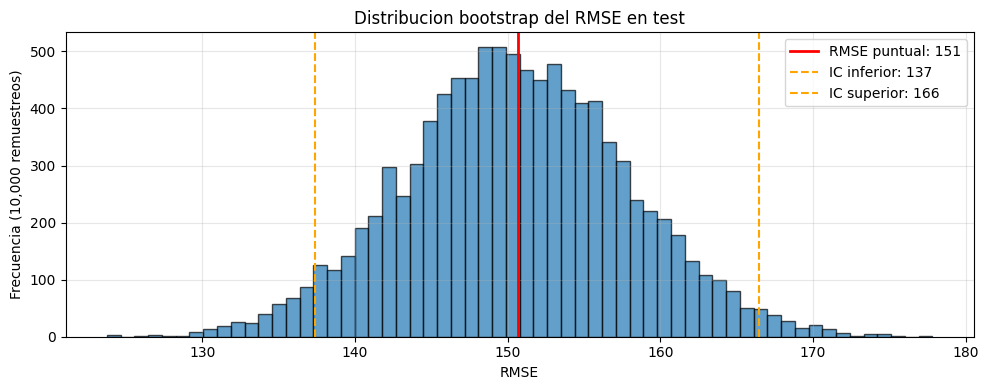

In [25]:
plt.figure(figsize=(10, 4))
plt.hist(resultado_boot.bootstrap_distribution, bins=60, edgecolor='black', alpha=0.7)
plt.axvline(final_rmse_rl, color='red', linewidth=2, label=f'RMSE puntual: {final_rmse_rl:,.0f}')
plt.axvline(rmse_lower, color='orange', linestyle='--', label=f'IC inferior: {rmse_lower:,.0f}')
plt.axvline(rmse_upper, color='orange', linestyle='--', label=f'IC superior: {rmse_upper:,.0f}')
plt.xlabel('RMSE')
plt.ylabel('Frecuencia (10,000 remuestreos)')
plt.title('Distribucion bootstrap del RMSE en test')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 14. Regularización con ElasticNetCV

## 14.1 Entrenamiento de ElasticNetCv y Selección de Features

In [26]:
from sklearn.linear_model import ElasticNetCV


model=Pipeline([("preprocesador",preprocesador),("Escalador",StandardScaler()),
                  ("elastic",ElasticNetCV(cv=tscv,
                  random_state=42,l1_ratio=[.1,.5,.7,.9,.95,1],
                 max_iter=200000,
        tol=0.001))])
model.fit(X_train,Y_train)

enet=model[-1]


print(enet.alpha_,enet.l1_ratio_)


coeficientes_elt=pd.Series(model.named_steps['elastic'].coef_,index=reg_pipe.named_steps['preprocesador'].get_feature_names_out())
Features_descartadas=coeficientes_elt.copy()
Features_descartadas=Features_descartadas.to_frame()
coeficientes_elt=coeficientes_elt[coeficientes_elt!=0]
coeficientes_elt.sort_values(ascending=False)
Features_descartadas.columns = ['Peso']
Features_descartadas['Estado']=Features_descartadas.apply(lambda x: 'Descartada' if x['Peso']==0 else 'Usada',axis=1)
Features_descartadas['Selección']=Features_descartadas.apply(lambda x: 'X' if x['Peso']==0 else '✓',axis=1)

Features_descartadas=Features_descartadas.style.set_properties(**{
    'text-align': 'center'
})
Features_descartadas





0.4389637161583922 1.0


,Peso,Estado,Selección
Mes__Mes_sin,10.287187,Usada,✓
Mes__Mes_cos,0.000000,Descartada,X
Dia__Fecha_Monday,164.263835,Usada,✓
Dia__Fecha_Saturday,103.719138,Usada,✓
Dia__Fecha_Thursday,-49.227383,Usada,✓
Dia__Fecha_Tuesday,-137.120262,Usada,✓
Dia__Fecha_Wednesday,-86.295782,Usada,✓
Semana__Fecha,-0.084551,Usada,✓
remainder__Feriado,30.733856,Usada,✓
remainder__Feriado_Largo,62.670883,Usada,✓


## 14.2 Comparación de Coeficientes  θ

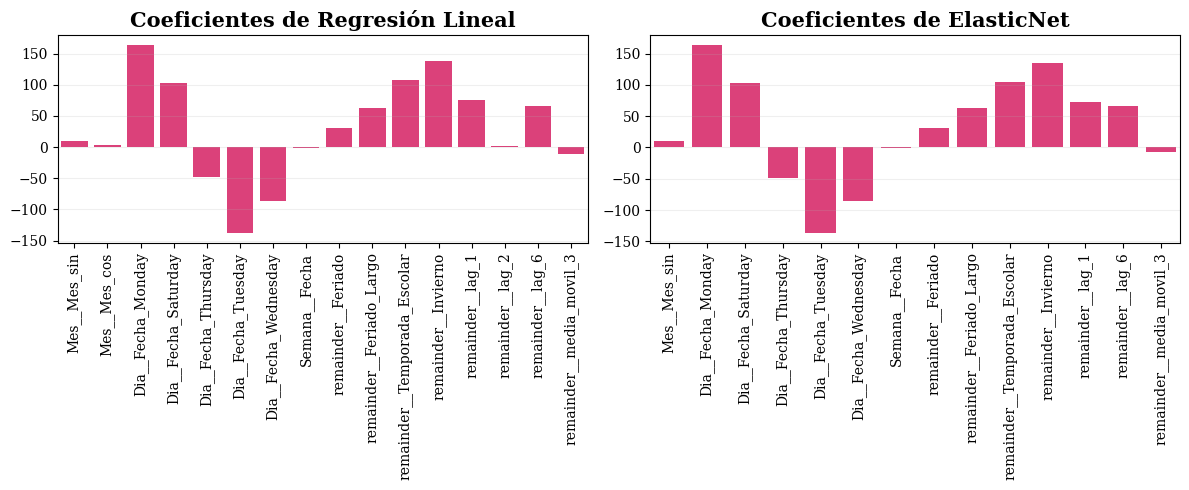

In [27]:
# Función para graficar
def bar(ax,coefs,title):
  sns.barplot(x=coefs.index,y=coefs.values,ax=ax,color='#F52773')
  ax.set_title(title,fontname="DejaVu Serif",fontweight="bold",fontsize=15)
  ax.set_ylabel("Importancia",fontname="DejaVu Serif")
  ax.grid(alpha=0.2,axis="y")
  ax.tick_params(axis='x', rotation=90)


 #Extraer los coeficientes  θ de la regresión lineal sin regularizar
coeficientes_rl=pd.Series(reg_pipe.named_steps['regresion'].coef_,index=reg_pipe.named_steps['preprocesador'].get_feature_names_out())


#Visualizar los pesos  de los coeficientes θ de ambos modelos
fig,ax=plt.subplots(1,2,figsize=(12,5))
bar(ax[0],coeficientes_rl,"Coeficientes de Regresión Lineal")
estilo_ejes(None,ax[0],None,None)
bar(ax[1],coeficientes_elt,"Coeficientes de ElasticNet")
estilo_ejes(None,ax[1],None,None)
plt.tight_layout()
plt.show()

## 14.3 Comparación de Desempeño

In [32]:

import time

# Obtener el RMSE train medio
RMSE_elt_medio =np.round((-cross_val_score(model,X_train,Y_train,scoring="neg_root_mean_squared_error",cv=tscv)).mean(),2)
RMSE_ln_medio=np.round(lin_rmse.mean(),2)


# Obtener el RMSE test
RMSE_elt_test=np.round(root_mean_squared_error(Y_test,model.predict(X_test)),2)
RMSE_ln_test=np.round(final_rmse_rl,2)


# Guardarlos en un DF
resultados = pd.DataFrame({'Conjunto': ['Train','Train','Test','Test'],
    'Modelo': ['Regresión Lineal','ElasticNet','Regresión Lineal','ElasticNet'],
    'RMSE': [RMSE_ln_medio,RMSE_elt_medio,RMSE_ln_test, RMSE_elt_test]
})

# Guardamos la cantidad de Features usados por ambos modelos
Features = pd.DataFrame({'Modelo':['Regresión Lineal','ElasticNet'],
                        'Cantidad':[len(coeficientes_rl),len(coeficientes_elt)]})

# Creamos una función para obtener el tiempo de predicción de los modelos
def medir_tiempo(modelo, X_test, repeticiones=30):
    tiempos = []
    for i in range(repeticiones):
        inicio = time.perf_counter()
        modelo.predict(X_test)
        fin = time.perf_counter()
        tiempos.append(fin - inicio)
    return np.mean(tiempos) * 1000


# Calculamos los resultados
tiempo_elastic=medir_tiempo(model,X_test)
tiempo_rl=medir_tiempo(reg_pipe,X_test)


# Guardamos los resultados obtenidos en un DF
tiempototal=pd.DataFrame({'Modelo':['Regresión Lineal','ElasticNetCV'],
                        'Tiempo':[tiempo_rl,tiempo_elastic]})





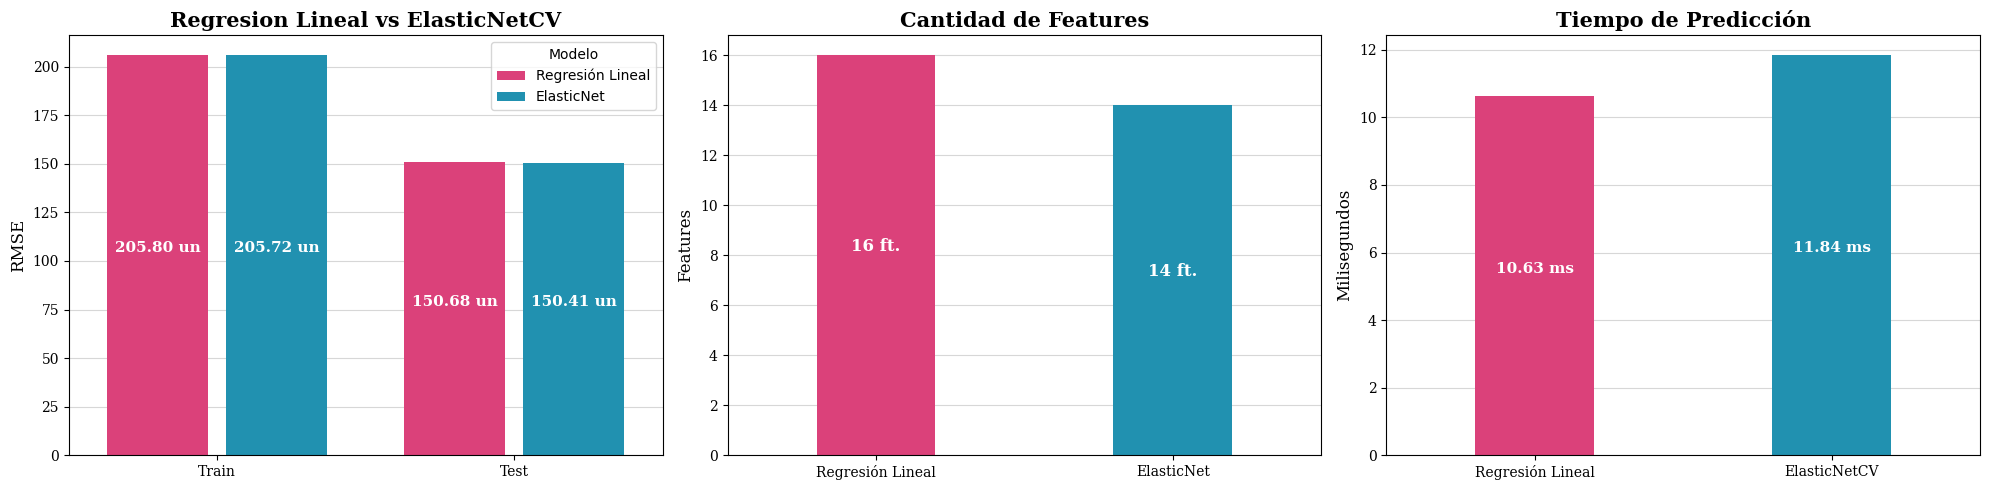


CONCLUSIÓN FINAL

- La Regresión Lineal obtuvo el mejor desempeño entre los modelos evaluados inicialmente.
- Al aplicar ElasticNet con un L1_ratio = 1, se redujo la cantidad de características de 16 a 14 (12.5% menos variables).
- ElasticNet obtuvo un RMSE de prueba de 150.41, ligeramente inferior al de la Regresión Lineal (150.68).
- Se mantuvo prácticamente el mismo rendimiento predictivo utilizando menos variables.
- Aunque el tiempo de predicción aumentó ligeramente (de 10.63 ms a 11.84 ms), se consiguió un modelo más compacto.
- Por tanto, se selecciona ElasticNet como modelo final, priorizando el equilibrio entre rendimiento predictivo, simplicidad e interpretabilidad.

En definitiva, se consiguió un modelo más sencillo sin sacrificar significativamente su capacidad predictiva.



In [37]:
fig, ax = plt.subplots(1,3,figsize=(20, 5))

# Gráfico comparativo del desempeño predictivo de los modelos según el RMSE
bar1=sns.barplot(data=resultados,x='Conjunto',y='RMSE',ax=ax[0],hue='Modelo',width=0.8,gap=0.15,palette={'Regresión Lineal':'#F52773',
                                                                                                         'ElasticNet':'#099EC8'})
estilo_ejes(None,ax[0],None,"RMSE")
ax[0].grid(alpha=0.5,axis="y")
ax[0].set_axisbelow(True)
ax[0].set_title('Regresion Lineal vs ElasticNetCV',fontname="DejaVu Serif",fontweight="bold",fontsize=15)
for b in bar1.patches:
    val = b.get_height()
    if val > 0:
        ax[0].text(b.get_x() + b.get_width()/2, val/2, f"{val:.2f} un", ha='center' ,va='bottom'
        , fontweight='bold',fontname='DejaVu Serif',color='white',fontsize=11)



# Gráfico comparativo de la cantidad de Features usados en cada modelo

bar2=sns.barplot(data=Features,x='Modelo',y='Cantidad',ax=ax[1],hue='Modelo',width=0.4,palette={'Regresión Lineal':'#F52773',
                                                                                       'ElasticNet':'#099EC8'})
estilo_ejes(None,ax[1],None,"Features")
ax[1].grid(alpha=0.5,axis="y")
ax[1].set_axisbelow(True)
ax[1].set_title("Cantidad de Features",fontname="DejaVu Serif",fontweight="bold",fontsize=15)
for b in bar2.patches:
    val = b.get_height()
    if val > 0:
        ax[1].text(b.get_x() + b.get_width()/2, val/2, f"{val:.0f} ft.", ha='center' ,va='bottom'
        , fontweight='bold',fontname='DejaVu Serif',color='white',fontsize=12)



# Gráfico comparativo del tiempo de predicción de cada modelo
tiempo=sns.barplot(data=tiempototal,x='Modelo',y='Tiempo',ax=ax[2],hue='Modelo',width=0.4,palette={'Regresión Lineal':'#F52773',
                                                                                                         'ElasticNetCV':'#099EC8'})
ax[2].grid(alpha=0.5,axis="y")
ax[2].set_axisbelow(True)
ax[2].set_title('Tiempo de Predicción',fontname="DejaVu Serif",fontweight="bold",fontsize=15)
estilo_ejes(None,ax[2],None,"Milisegundos")
for b in tiempo.patches:
    val = b.get_height()
    if val > 0:
        ax[2].text(b.get_x() + b.get_width()/2, val/2, f"{val:.2f} ms", ha='center' ,va='bottom'
        , fontweight='bold',fontname='DejaVu Serif',color='white',fontsize=11)
plt.tight_layout()
plt.show()


print("""
CONCLUSIÓN FINAL

- La Regresión Lineal obtuvo el mejor desempeño entre los modelos evaluados inicialmente.
- Al aplicar ElasticNet con un L1_ratio = 1, se redujo la cantidad de características de 16 a 14 (12.5% menos variables).
- ElasticNet obtuvo un RMSE de prueba de 150.41, ligeramente inferior al de la Regresión Lineal (150.68).
- Se mantuvo prácticamente el mismo rendimiento predictivo utilizando menos variables.
- Aunque el tiempo de predicción aumentó ligeramente (de 10.63 ms a 11.84 ms), se consiguió un modelo más compacto.
- Por tanto, se selecciona ElasticNet como modelo final, priorizando el equilibrio entre rendimiento predictivo, simplicidad e interpretabilidad.

En definitiva, se consiguió un modelo más sencillo sin sacrificar significativamente su capacidad predictiva.
""")
